## Лабораторная работа №1. Регрессия и метод главных компонент
**Цель работы:** изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качества.

**Задачи:**
1) Загрузить датасет из репозитория

2) Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной. 
3) Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).
4) Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).
5) Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).
6) Построить график остатков моделей (добавить горизонтальную линию на уровне 0) и исследовать структуру остатков на предмет гомоскедастичности или гетероскедастичности.
7) Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.
8) Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.
### Ход работы

#### 2. Описание датасета
Для выполнения лабораторной работы выбран набор данных Life Expectancy (WHO), опубликованный на платформе Kaggle.
Источник: https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who

Датасет содержит статистические показатели, характеризующие ожидаемую продолжительность жизни населения различных стран мира за период с 2000 по 2015 год.
В наборе представлены демографические, медицинские, социальные и экономические показатели, в том числе уровень смертности, охват вакцинацией, ВВП, расходы на здравоохранение и продолжительность обучения.
Целевая переменная - Life expectancy, ожидаемая продолжительность жизни в годах.
Поскольку целевая переменная является количественной, для её прогнозирования будут использованы методы линейной регрессии, Lasso и Ridge.

#### 2.1. Загрузка и первичный анализ данных

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/Life Expectancy Data.csv")

df.columns = df.columns.str.strip()

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


В результате загрузки установлено, что исходный датасет содержит **2938 наблюдений и 22 столбца**.

Каждая строка представляет собой наблюдение для определённой страны за конкретный год.

Для загрузки данных использовалась библиотека `pandas` и функция `read_csv()`. Дополнительно выполнено удаление лишних пробелов из названий столбцов с помощью метода `str.strip()`.

Полученный набор данных пригоден для дальнейшего регрессионного анализа, однако требует проверки типов признаков, пропущенных значений и возможных выбросов.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

Анализ структуры датасета показал наличие числовых и категориальных переменных.

К категориальным признакам относятся `Country` и `Status`. Остальные столбцы представлены числовыми данными.

Столбец `Country` содержит названия стран, а `Status` характеризует уровень развития страны.

Для обучения регрессионных моделей потребуется преобразовать категориальный признак `Status` в числовой формат, а столбец `Country` использовать для группировки наблюдений при разделении выборки.

Количество непустых значений в некоторых столбцах меньше общего числа наблюдений, что указывает на наличие пропусков.

#### 2.2. Описательные статистики

Для числовых признаков рассчитаны основные описательные статистики: количество наблюдений, среднее значение, стандартное отклонение, минимальное и максимальное значения, а также квартили.

Анализ показал, что признаки имеют существенно различающиеся масштабы. Например, показатель `Income composition of resources` принимает значения от 0 до 1, тогда как `Population` измеряется количеством жителей.

Целевая переменная `Life expectancy` в исходном наборе принимает значения от 36,3 до 89 лет.

Существенные различия масштабов признаков необходимо учитывать при обучении регрессионных моделей с регуляризацией и применении метода главных компонент. Для этого в дальнейшем будет использована стандартизация данных.

In [16]:
statistics = df.describe().T

display(statistics.round(2))

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2007.52,4.61,2000.00,2004.00,2008.00,2012.00,2.015000e+03
Life expectancy,2928.0,69.22,9.52,36.30,63.10,72.10,75.70,8.900000e+01
Adult Mortality,2928.0,164.80,124.29,1.00,74.00,144.00,228.00,7.230000e+02
infant deaths,2938.0,30.30,117.93,0.00,0.00,3.00,22.00,1.800000e+03
Alcohol,2744.0,4.60,4.05,0.01,0.88,3.76,7.70,1.787000e+01
percentage expenditure,2938.0,738.25,1987.91,0.00,4.69,64.91,441.53,1.947991e+04
Hepatitis B,2385.0,80.94,25.07,1.00,77.00,92.00,97.00,9.900000e+01
Measles,2938.0,2419.59,11467.27,0.00,0.00,17.00,360.25,2.121830e+05
BMI,2904.0,38.32,20.04,1.00,19.30,43.50,56.20,8.730000e+01
under-five deaths,2938.0,42.04,160.45,0.00,0.00,4.00,28.00,2.500000e+03


#### 2.3. Распределение целевой переменной

Для исследования распределения ожидаемой продолжительности жизни построена гистограмма с наложенной сглаженной оценкой плотности.

На рисунке представлено распределение ожидаемой продолжительности жизни населения в различных странах за период 2000–2015 годов.


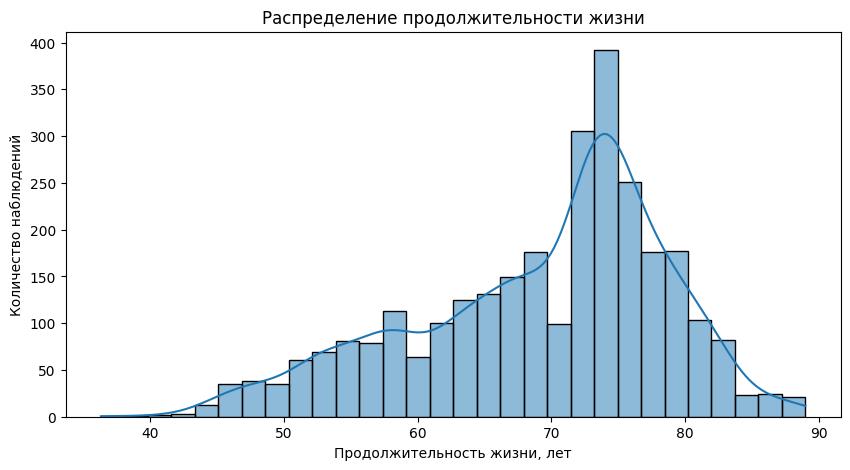

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Life expectancy",
    bins=30,
    kde=True
)

plt.title("Распределение продолжительности жизни")
plt.xlabel("Продолжительность жизни, лет")
plt.ylabel("Количество наблюдений")

plt.show()

Анализ гистограммы показывает, что наибольшее количество наблюдений приходится на диапазон продолжительности жизни примерно от 72 до 77 лет. Максимальная частота наблюдается около 74-75 лет.

Распределение имеет отрицательную асимметрию: левый хвост более вытянут, что свидетельствует о наличии наблюдений с относительно низкой продолжительностью жизни. При этом значения выше 85 лет встречаются значительно реже.

Таким образом, распределение целевой переменной отличается от нормального. Наблюдаемые различия в продолжительности жизни обосновывают необходимость исследования её зависимости от демографических, медицинских и социально-экономических показателей.

#### 2.4. Анализ распределений признаков

Для исследования количественных характеристик датасета построены гистограммы распределений всех числовых признаков.


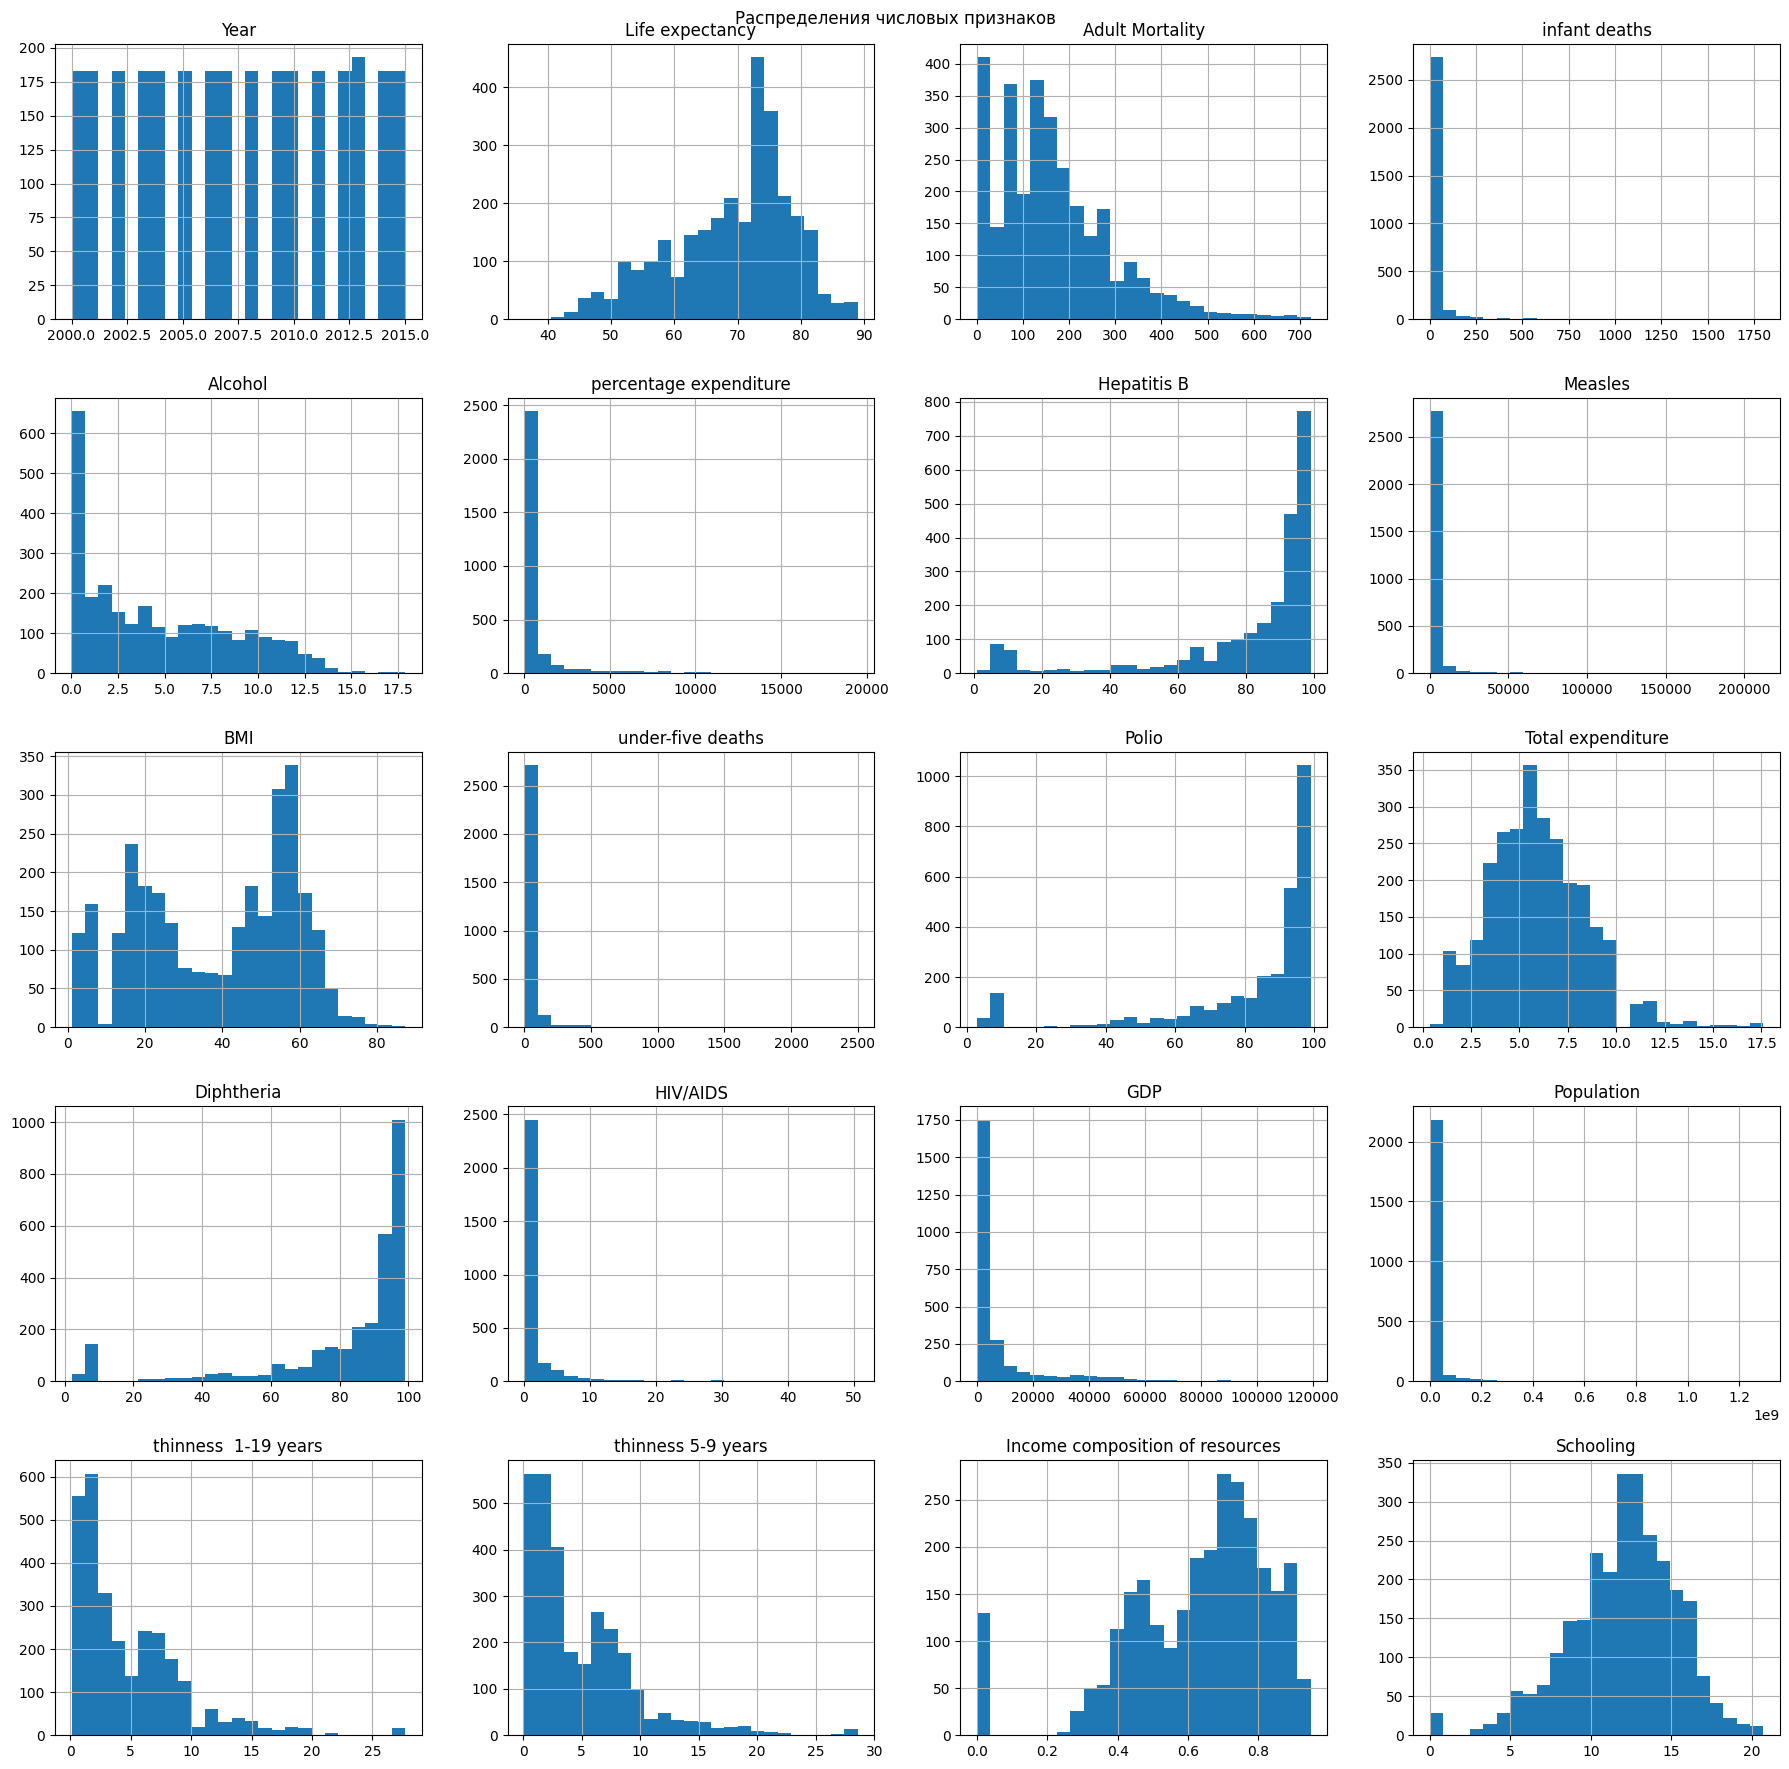

In [14]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

df[numeric_columns].hist(
    figsize=(18, 18),
    bins=25
)

plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.show()

Анализ гистограмм показал, что числовые признаки имеют различные распределения и масштабы значений. Для показателей `GDP`, `Population`, `infant deaths` и `under-five deaths` характерна выраженная правосторонняя асимметрия: большинство наблюдений сосредоточено в области небольших значений. Показатели вакцинации `Polio`, `Diphtheria` и `Hepatitis B` преимущественно принимают высокие значения.

Распределения некоторых признаков содержат потенциальные выбросы. Существенные различия масштабов подтверждают необходимость стандартизации данных перед регуляризацией и применением PCA.

#### 2.5. Зависимость целевой переменной от признаков

Для предварительного исследования связей между ожидаемой продолжительностью жизни и независимыми признаками построены диаграммы рассеяния.

В анализ включены показатели `Schooling`, `Adult Mortality`, `GDP` и `BMI`.

Диаграммы позволяют визуально оценить направление зависимости целевой переменной от каждого фактора, выявить возможную нелинейность и наличие отдельных наблюдений, существенно отличающихся от остальных.


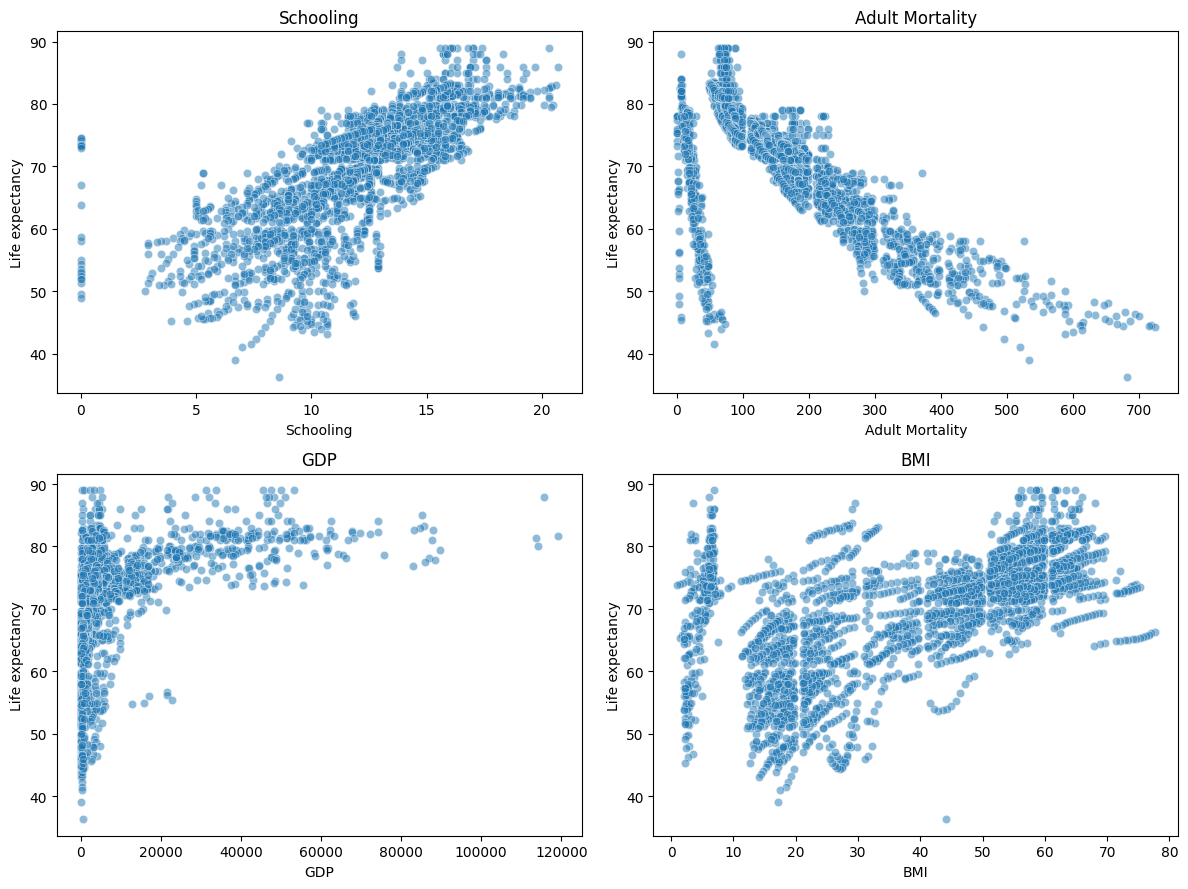

In [12]:
features = [
    "Schooling",
    "Adult Mortality",
    "GDP",
    "BMI"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flat, features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="Life expectancy",
        alpha=0.5,
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

Анализ графиков позволяет сделать следующие выводы:

1. **Schooling (продолжительность обучения).** Наблюдается выраженная положительная зависимость: с увеличением продолжительности обучения ожидаемая продолжительность жизни, как правило, возрастает. Расположение точек указывает на связь, близкую к линейной.

2. **Adult Mortality (смертность взрослого населения).** Прослеживается сильная отрицательная зависимость: при увеличении уровня смертности взрослых ожидаемая продолжительность жизни снижается. При этом на графике присутствуют отдельные группы наблюдений, отличающиеся от основной тенденции.

3. **GDP (ВВП на душу населения).** Наблюдается положительная, но нелинейная зависимость. При относительно низких значениях GDP продолжительность жизни имеет значительный разброс, тогда как при высоких значениях GDP она преимущественно находится в верхней части диапазона. Дальнейшее увеличение GDP не сопровождается столь же выраженным ростом продолжительности жизни.

4. **BMI (индекс массы тела).** Наблюдается общая положительная тенденция, однако точки имеют значительный разброс. Это свидетельствует о менее выраженной и неоднородной зависимости по сравнению с показателями Schooling и Adult Mortality.


#### 2.6. Корреляционный анализ

Для исследования взаимосвязей между числовыми признаками датасета построена корреляционная матрица.

Корреляционный анализ позволяет определить силу и направление линейной зависимости между переменными, выявить признаки, наиболее тесно связанные с целевой переменной, а также обнаружить возможную мультиколлинеарность.

Для расчёта используется коэффициент корреляции Пирсона, принимающий значения от -1 до 1:

- **r = 1** - идеальная положительная линейная связь;
- **r = -1** - идеальная отрицательная линейная связь;
- **r ≈ 0** - отсутствие или слабая линейная связь.

Чем ближе абсолютное значение коэффициента к единице, тем сильнее линейная зависимость между признаками.

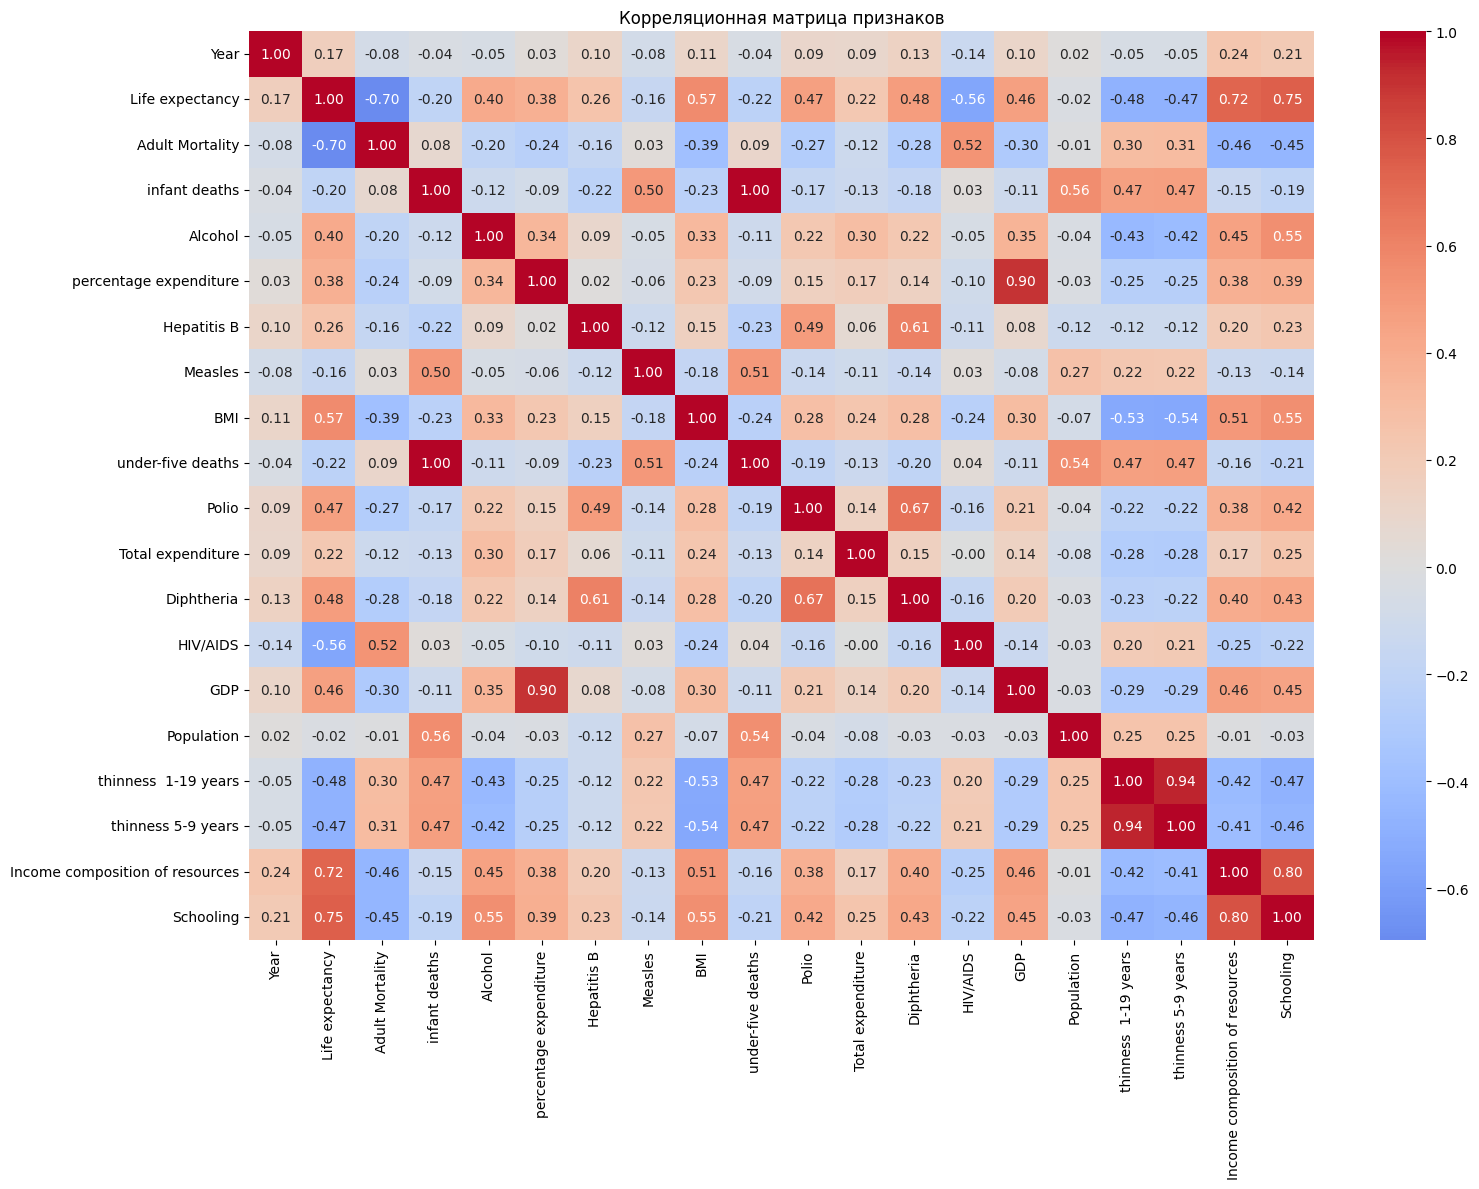

In [17]:
corr_matrix = df.select_dtypes(
    include=np.number
).corr(method="pearson")

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

#### 3. Подготовка данных

Перед обучением регрессионных моделей необходимо провести предобработку данных. Она включает проверку пропущенных значений и дубликатов, анализ выбросов, удаление неполных наблюдений, кодирование категориальных признаков и разделение данных на обучающую и тестовую выборки.


#### 3.1. Анализ пропущенных значений

Пропущенные значения могут препятствовать обучению регрессионных моделей и влиять на достоверность результатов. Для определения количества пропусков в каждом столбце используется метод `isna()`. Полученные значения представлены в виде столбчатой диаграммы.

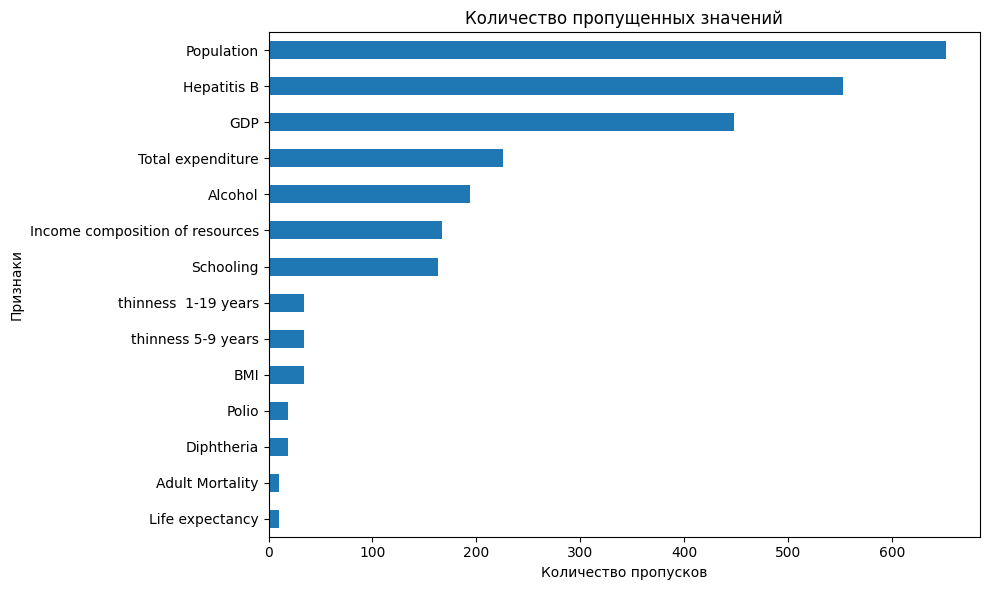

In [18]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()

plt.figure(figsize=(10, 6))
missing.plot(kind="barh")

plt.title("Количество пропущенных значений")
plt.xlabel("Количество пропусков")
plt.ylabel("Признаки")

plt.tight_layout()
plt.show()

Наибольшее количество пропусков наблюдается в признаках Population (652), Hepatitis B (553) и GDP (448). Пропущенные значения присутствуют также в других столбцах, включая целевую переменную Life expectancy.

Наличие пропусков указывает на необходимость очистки данных перед обучением регрессионных моделей.

#### 3.2. Проверка дубликатов

Дублирующиеся наблюдения могут искажать результаты анализа и влиять на обучение моделей. Для проверки наличия одинаковых строк используется метод `duplicated()` библиотеки pandas.

Дополнительно проверяется уникальность сочетаний страны и года, поскольку каждое наблюдение должно соответствовать определённой стране за конкретный год.

In [19]:
print("Полных дубликатов:", df.duplicated().sum())

print(
    "Дубликатов по стране и году:",
    df.duplicated(subset=["Country", "Year"]).sum()
)

Полных дубликатов: 0
Дубликатов по стране и году: 0


В результате проверки установлено, что в исходном датасете отсутствуют полные дубликаты строк. Это позволяет сохранить имеющиеся наблюдения без дополнительного удаления повторяющихся записей.

#### 3.3. Анализ выбросов

Выбросы представляют собой значения, значительно отличающиеся от основной массы наблюдений. Их наличие может влиять на коэффициенты регрессионных моделей и величину ошибок прогнозирования.

Для визуального исследования выбросов используются диаграммы размаха (boxplot) для целевой переменной и отдельных числовых признаков.

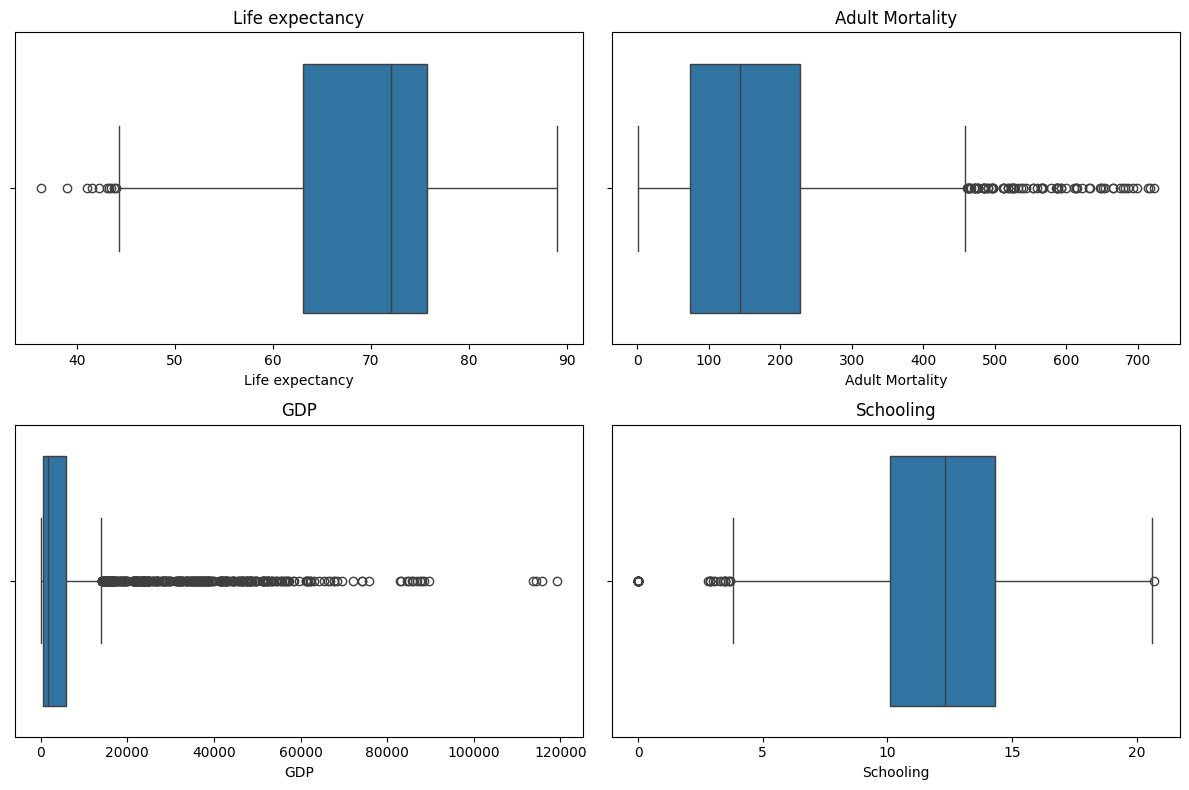

In [20]:
features = [
    "Life expectancy",
    "Adult Mortality",
    "GDP",
    "Schooling"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(data=df, x=feature, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

На диаграммах наблюдаются потенциальные выбросы, особенно в признаках GDP и Adult Mortality. Они могут отражать реальные экономические и демографические различия между странами.

Было принято решение не удалять выбросы автоматически, поскольку это могло бы привести к потере значимой информации. В дальнейшем их возможное влияние будет учитываться при оценке качества моделей.

#### 3.4. Удаление пропущенных значений

Для подготовки датасета к моделированию используется метод удаления строк с пропущенными значениями `dropna()`. Такой подход позволяет получить набор данных, не содержащий пропусков, и использовать его непосредственно для обучения регрессионных моделей.

Недостатком метода является сокращение количества наблюдений.



In [8]:
df_clean = df.dropna().copy()

print("До очистки:", df.shape)
print("После очистки:", df_clean.shape)
print("Удалено строк:", len(df) - len(df_clean))

До очистки: (2938, 22)
После очистки: (1649, 22)
Удалено строк: 1289


После применения метода dropna() количество наблюдений сократилось с 2938 до 1649. Было удалено 1289 строк, что составляет приблизительно 43,9% исходного набора данных.

В результате сформирован датасет без пропущенных значений. Несмотря на существенное сокращение объёма выборки, оставшихся наблюдений достаточно.

#### 3.5. Кодирование категориальных признаков

Регрессионные модели библиотеки scikit-learn работают с числовыми признаками. Поэтому категориальные переменные необходимо преобразовать в числовой формат.

В датасете присутствуют два категориальных столбца: `Country` и `Status`. Признак `Status` содержит две категории - `Developed` и `Developing`, поэтому для него применяется бинарное кодирование.

Столбец `Country` исключается из матрицы признаков, но сохраняется для группового разделения данных.

In [12]:
df_clean["Status"] = df_clean["Status"].replace({
    "Developing": 0,
    "Developed": 1
}).astype(int)

print(df_clean["Status"].value_counts())

Status
0    1407
1     242
Name: count, dtype: int64


C:\Users\vanya\AppData\Local\Temp\ipykernel_21424\826479786.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean["Status"] = df_clean["Status"].replace({


#### 3.6. Формирование обучающей и тестовой выборок

Для построения моделей данные разделяются на матрицу независимых признаков X и целевую переменную y.

В качестве целевой переменной используется `Life expectancy`, а из матрицы признаков исключается столбец `Country`.

Поскольку набор данных содержит повторные наблюдения одних и тех же стран за разные годы, применяется групповое разделение `GroupShuffleSplit`. Оно позволяет исключить попадание одной страны одновременно в обучающую и тестовую выборки.

Для тестирования выделяется приблизительно 20% стран, остальные используются для обучения моделей.

Обучающая выборка: (1304, 20)
Тестовая выборка: (345, 20)
Общие страны: set()


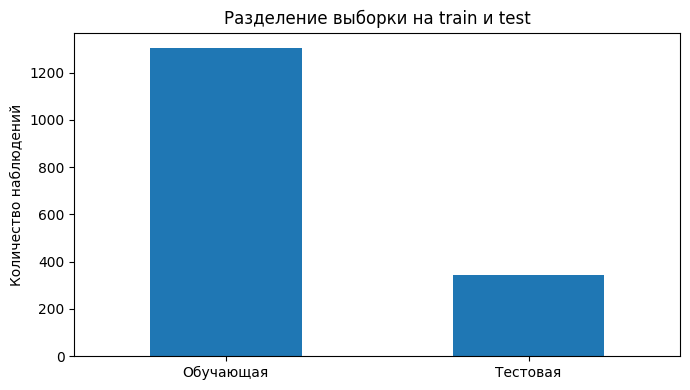

In [16]:
from sklearn.model_selection import GroupShuffleSplit

X = df_clean.drop(columns=["Country", "Life expectancy"])
y = df_clean["Life expectancy"]
groups = df_clean["Country"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

print(
    "Общие страны:",
    set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
)

sizes = pd.Series({
    "Обучающая": len(X_train),
    "Тестовая": len(X_test)
})

sizes.plot(kind="bar", figsize=(7, 4))
plt.title("Разделение выборки на train и test")
plt.ylabel("Количество наблюдений")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Данные разделены на обучающую и тестовую выборки с использованием метода GroupShuffleSplit. Разделение выполнялось по странам, что исключает пересечение наблюдений одной страны между двумя выборками.

Параметр random_state=42 обеспечивает воспроизводимость результатов. Все последующие модели будут обучаться и оцениваться с использованием одинакового разделения данных, что позволяет корректно сравнивать их качество.

#### 3.7. Стандартизация признаков

Числовые признаки датасета имеют различные масштабы. Например, показатель `Income composition of resources` находится в диапазоне от 0 до 1, тогда как `GDP` и `Population` могут принимать значительно большие значения.

Для приведения признаков к единому масштабу используется метод стандартизации `StandardScaler`, который преобразует значения так, чтобы каждый признак имел среднее, близкое к нулю, и стандартное отклонение, близкое к единице.

Стандартизация особенно важна для моделей Lasso, Ridge и метода главных компонент (PCA).

В ходе дальнейшего обучения преобразование будет включено в `Pipeline`. Это позволит вычислять параметры стандартизации только на обучающих данных каждого разбиения кросс-валидации и избежать утечки информации из тестовой выборки.

#### 4. Ход работы

4.1. Анализ мультиколлинеарности

Мультиколлинеарность возникает, когда независимые признаки регрессионной модели имеют сильные линейные зависимости друг от друга. Это может приводить к нестабильности коэффициентов линейной регрессии и затруднять их интерпретацию.

Для оценки мультиколлинеарности используется коэффициент VIF (Variance Inflation Factor), рассчитываемый по формуле:

$$VIF_i = \frac{1}{1 - R_i^2}$$

Значения VIF, близкие к 1, указывают на отсутствие существенной мультиколлинеарности, а значения выше 5–10 могут свидетельствовать о выраженной зависимости признаков.

Расчёт выполняется на обучающей выборке без включения целевой переменной.

In [17]:
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

vif_table = pd.DataFrame({
    "Признак": X_train.columns,
    "VIF": [
        variance_inflation_factor(X_scaled, i)
        for i in range(X_scaled.shape[1])
    ]
})

vif_table = vif_table.sort_values("VIF", ascending=False)

display(vif_table.round(2))

,Признак,VIF
3,infant deaths,221.02
9,under-five deaths,210.66
14,GDP,13.99
5,percentage expenditure,13.15
16,thinness 1-19 years,7.33
17,thinness 5-9 years,7.28
19,Schooling,3.54
18,Income composition of resources,2.99
4,Alcohol,2.65
12,Diphtheria,2.14


По результатам расчёта VIF можно определить признаки с наиболее выраженной мультиколлинеарностью.

Высокие значения VIF свидетельствуют о том, что часть информации отдельных признаков может быть объяснена другими независимыми переменными.

Для снижения мультиколлинеарности в дальнейшем будет применён метод главных компонент (PCA), преобразующий исходные признаки в новые некоррелированные компоненты.

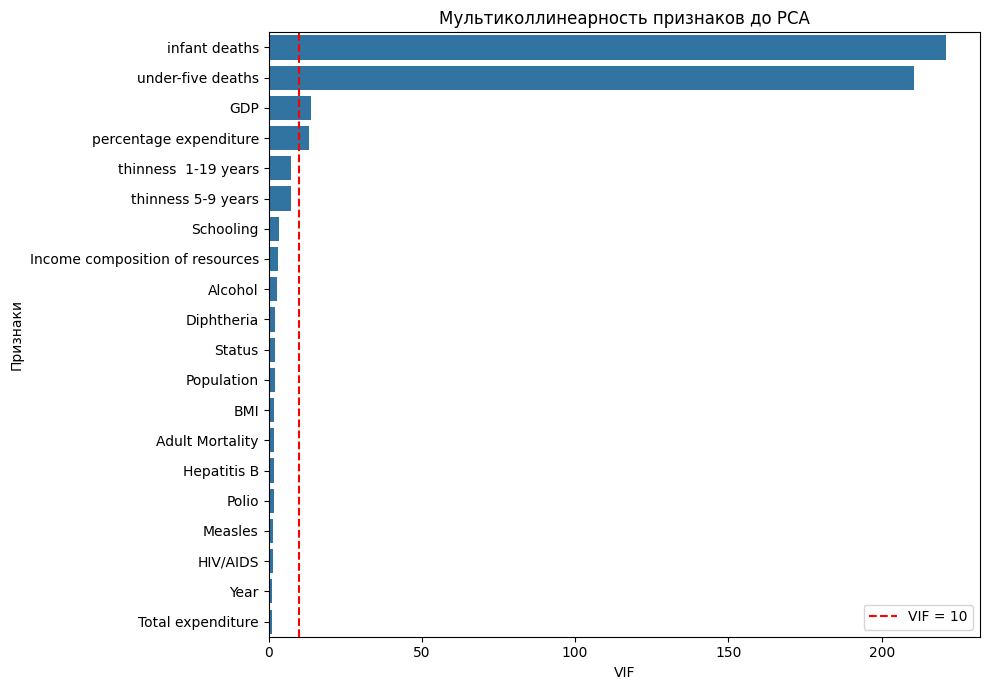

In [18]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=vif_table,
    x="VIF",
    y="Признак"
)

plt.axvline(10, color="red", linestyle="--", label="VIF = 10")

plt.title("Мультиколлинеарность признаков до PCA")
plt.xlabel("VIF")
plt.ylabel("Признаки")
plt.legend()

plt.tight_layout()
plt.show()

На диаграмме представлены значения коэффициентов VIF для исходных независимых переменных. Красная пунктирная линия соответствует пороговому значению VIF = 10.

Признаки, коэффициенты которых превышают указанный уровень, требуют дополнительного анализа на наличие сильной мультиколлинеарности.

Полученные результаты позволяют обосновать необходимость применения PCA для преобразования исходного признакового пространства.

#### 4.2. Построение регрессионных моделей

Для прогнозирования ожидаемой продолжительности жизни используются три алгоритма:

Linear Regression - классическая линейная регрессия, минимизирующая сумму квадратов ошибок.

Lasso Regression - линейная регрессия с L1-регуляризацией, способной уменьшать отдельные коэффициенты до нуля.

Ridge Regression - линейная регрессия с L2-регуляризацией, уменьшающей величину коэффициентов модели.

Для всех моделей применяется стандартизация признаков с помощью StandardScaler.

Преобразование и модель объединяются в Pipeline. Это обеспечивает выполнение стандартизации внутри каждого разбиения кросс-валидации и предотвращает утечку информации из проверочной выборки.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge

models = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=10000))
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ])
}

print("Созданы модели:")
for name in models:
    print(name)

Созданы модели:
Linear
Lasso
Ridge


Созданы три модели регрессии: Linear Regression, Lasso и Ridge.

Каждая модель включает этап стандартизации независимых признаков. Это обеспечивает сопоставимость масштабов переменных и корректное применение регуляризации.

Для Lasso задано максимальное количество итераций `max_iter=10000`, необходимое для повышения вероятности сходимости алгоритма.

Коэффициент регуляризации `alpha` для Lasso и Ridge будет определён с помощью кросс-валидации.

#### 4.3. Кросс-валидация и подбор гиперпараметров

Для подбора параметров регрессионных моделей используется метод кросс-валидации.

В работе применяется `GroupKFold` с пятью разбиениями. Группировка проводится по странам, что исключает попадание наблюдений одной страны одновременно в обучающую и проверочную части одного разбиения.

Для моделей Lasso и Ridge подбирается коэффициент регуляризации `alpha` из набора значений: 0.001, 0.01, 0.1, 1, 10 и 100.

Оптимальные параметры определяются с помощью `GridSearchCV`. В качестве критерия качества используется RMSE - среднеквадратичная ошибка прогноза.

In [20]:
from sklearn.model_selection import GroupKFold, GridSearchCV

cv = GroupKFold(n_splits=5)

alphas = [0.001, 0.01, 0.1, 1, 10, 100]

trained_models = {}

for name, model in models.items():

    if name == "Linear":
        params = {}
    else:
        params = {"model__alpha": alphas}

    search = GridSearchCV(
        model,
        param_grid=params,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    search.fit(X_train, y_train, groups=groups_train)

    trained_models[name] = search.best_estimator_

    print(name)
    print("Лучшие параметры:", search.best_params_)
    print("RMSE при кросс-валидации:", round(-search.best_score_, 3))
    print()

Linear
Лучшие параметры: {}
RMSE при кросс-валидации: 3.768

Lasso
Лучшие параметры: {'model__alpha': 0.01}
RMSE при кросс-валидации: 3.71

Ridge
Лучшие параметры: {'model__alpha': 1}
RMSE при кросс-валидации: 3.689



В результате кросс-валидации для каждой модели определена средняя ошибка прогнозирования RMSE. Для Lasso и Ridge также подобраны значения коэффициента регуляризации `alpha`.

Использование пяти групповых разбиений позволяет оценить устойчивость моделей на различных подмножествах стран.

Модели с выбранными параметрами обучаются на всей тренировочной выборке. Окончательное сравнение их качества проводится отдельно на тестовых данных, которые не использовались для подбора параметров.

#### 4.4. Оценка качества регрессионных моделей

Для оценки точности прогнозирования используются три метрики:

- **RMSE (Root Mean Squared Error)** - среднеквадратичная ошибка, выраженная в годах. Чем меньше значение, тем точнее прогноз.
- **R² (коэффициент детерминации)** - характеризует долю вариации целевой переменной, объясняемую моделью. Чем выше значение, тем лучше качество модели.
- **MAPE (Mean Absolute Percentage Error)** - средняя абсолютная процентная ошибка прогноза. Чем меньше значение, тем лучше.

Метрики рассчитываются для обучающей и тестовой выборок. Их сравнение позволяет оценить качество прогнозирования и выявить возможное переобучение.

In [21]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

results = []

for name, model in trained_models.items():

    for sample, X_part, y_part in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test)
    ]:

        y_pred = model.predict(X_part)

        rmse = np.sqrt(mean_squared_error(y_part, y_pred))
        r2 = r2_score(y_part, y_pred)
        mape = mean_absolute_percentage_error(y_part, y_pred) * 100

        results.append({
            "Модель": name,
            "Выборка": sample,
            "RMSE": rmse,
            "R²": r2,
            "MAPE (%)": mape
        })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Модель,Выборка,RMSE,R²,MAPE (%)
0,Linear,Train,3.408,0.856,3.917
1,Linear,Test,4.175,0.729,5.065
2,Lasso,Train,3.421,0.855,3.937
3,Lasso,Test,4.181,0.728,5.062
4,Ridge,Train,3.414,0.856,3.925
5,Ridge,Test,4.181,0.728,5.062


По результатам тестирования проведено сравнение качества трёх регрессионных моделей по метрикам RMSE, R² и MAPE.

RMSE показывает величину ошибки прогноза в годах, R² характеризует объясняющую способность модели, а MAPE позволяет оценить среднюю относительную ошибку в процентах.

Для анализа переобучения дополнительно сравниваются результаты на обучающей и тестовой выборках. Значительное ухудшение показателей на тестовых данных может свидетельствовать о недостаточной обобщающей способности модели.

#### 4.5. Анализ остатков регрессионных моделей

Остатки представляют собой разность между фактическими и предсказанными значениями целевой переменной.

Анализ остатков позволяет определить, насколько систематически модель ошибается при прогнозировании, и исследовать предположение о постоянстве дисперсии ошибок.

**Гомоскедастичность** предполагает приблизительно одинаковый разброс остатков при различных значениях прогноза. **Гетероскедастичность** характеризуется изменением разброса остатков.

Для анализа строятся диаграммы зависимости остатков от предсказанных значений с горизонтальной линией на уровне нуля.

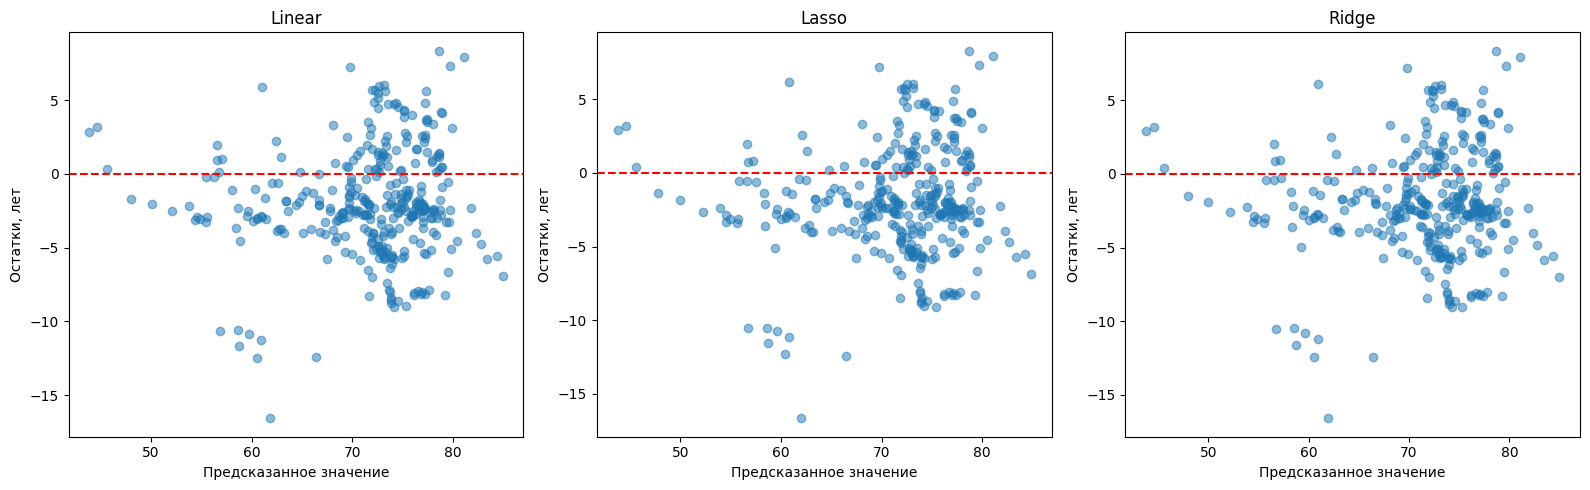

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    ax.scatter(y_pred, residuals, alpha=0.5)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Предсказанное значение")
    ax.set_ylabel("Остатки, лет")

plt.tight_layout()
plt.show()

Анализ графиков показывает, что все три модели имеют схожее распределение остатков. Большинство значений сосредоточено вблизи нулевой линии, однако присутствуют отдельные значительные отклонения, преимущественно в отрицательную сторону.

Распределение остатков не является полностью случайным: наблюдаются участки с различной плотностью и разбросом точек. Это позволяет предположить наличие гетероскедастичности, однако визуального анализа недостаточно для её однозначного подтверждения.

Таким образом, модели демонстрируют схожую структуру ошибок, а применение регуляризации Lasso и Ridge не привело к заметному изменению распределения остатков.

#### 4.6. Применение метода главных компонент (PCA)

Метод главных компонент (Principal Component Analysis, PCA) применяется для уменьшения размерности признакового пространства и устранения линейных зависимостей между преобразованными признаками.

PCA формирует новые переменные - главные компоненты, представляющие собой линейные комбинации исходных признаков. Компоненты являются взаимно ортогональными и упорядочиваются по доле объясняемой дисперсии.

Перед применением PCA необходимо выполнить стандартизацию признаков, поскольку исходные переменные имеют различные масштабы.

Количество главных компонент выбирается таким образом, чтобы сохранить не менее 95% общей дисперсии исходных стандартизированных признаков.

In [24]:
from sklearn.decomposition import PCA

scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)

pca = PCA()
pca.fit(X_train_scaled)

variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

print("Объяснённая дисперсия:")
print(np.round(variance, 3))

print("Накопленная дисперсия:")
print(np.round(cumulative_variance, 3))

Объяснённая дисперсия:
[0.298 0.147 0.094 0.075 0.063 0.053 0.041 0.039 0.034 0.03  0.025 0.02
 0.02  0.018 0.016 0.013 0.01  0.004 0.002 0.   ]
Накопленная дисперсия:
[0.298 0.445 0.539 0.613 0.676 0.729 0.77  0.808 0.842 0.872 0.897 0.917
 0.937 0.955 0.971 0.984 0.994 0.998 1.    1.   ]


В результате применения PCA рассчитаны доли дисперсии, объясняемые каждой главной компонентой.

Первые компоненты содержат наибольшую долю общей изменчивости исходных признаков. Последующие компоненты объясняют всё меньшую часть дисперсии.

Для выбора оптимального количества компонент далее строятся график каменистой осыпи и график накопленной объяснённой дисперсии.

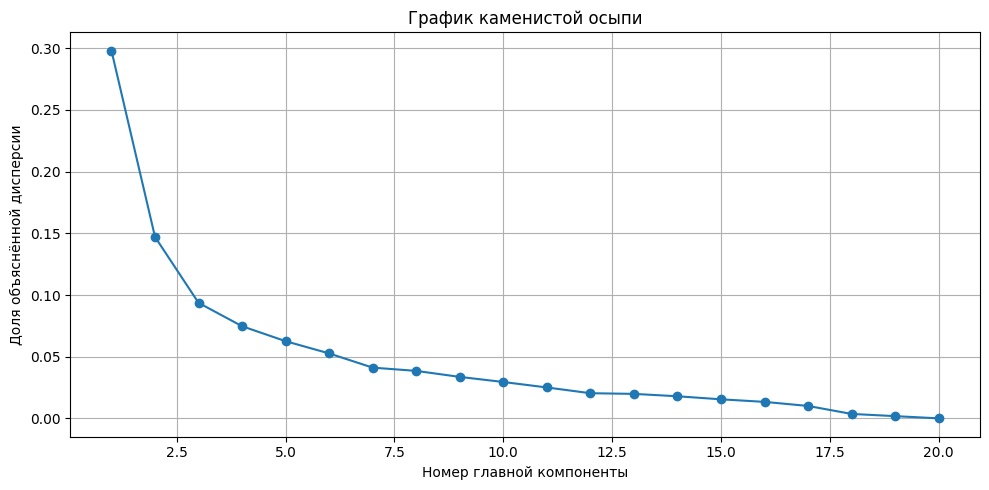

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(variance) + 1),
    variance,
    marker="o"
)

plt.title("График каменистой осыпи")
plt.xlabel("Номер главной компоненты")
plt.ylabel("Доля объяснённой дисперсии")

plt.grid(True)
plt.tight_layout()
plt.show()

График отображает долю общей дисперсии, объясняемую каждой главной компонентой.

По мере увеличения номера компоненты вклад в объяснение дисперсии постепенно уменьшается. Это позволяет определить возможность сокращения количества признаков без существенной потери информации об их общей изменчивости.

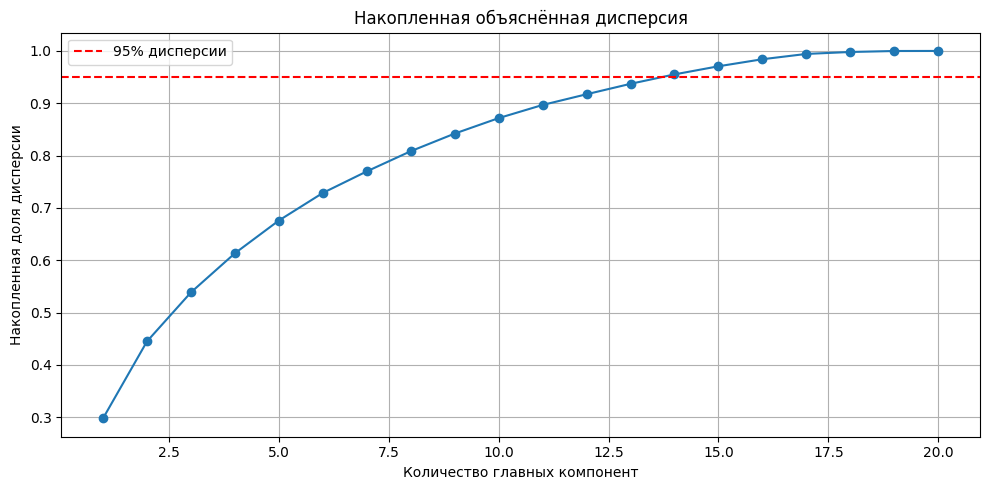

Выбрано компонент: 14


In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    0.95,
    color="red",
    linestyle="--",
    label="95% дисперсии"
)

plt.title("Накопленная объяснённая дисперсия")
plt.xlabel("Количество главных компонент")
plt.ylabel("Накопленная доля дисперсии")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Выбрано компонент:", n_components)

Красная пунктирная линия обозначает уровень сохранения 95% общей дисперсии.

Количество главных компонент определяется как минимальное число, при котором накопленная доля объяснённой дисперсии достигает указанного порога.

Выбранные компоненты будут использоваться вместо исходных признаков для повторного обучения моделей Linear Regression, Lasso и Ridge.

In [27]:
pca_selected = PCA(n_components=0.95)

X_pca = pca_selected.fit_transform(X_train_scaled)

vif_pca = [
    variance_inflation_factor(X_pca, i)
    for i in range(X_pca.shape[1])
]

vif_after = pd.DataFrame({
    "Компонента": [
        f"PC{i+1}" for i in range(len(vif_pca))
    ],
    "VIF": vif_pca
})

display(vif_after.round(3))

print("Размер до PCA:", X_train.shape)
print("Размер после PCA:", X_pca.shape)

,Компонента,VIF
0,PC1,1.0
1,PC2,1.0
2,PC3,1.0
3,PC4,1.0
4,PC5,1.0
5,PC6,1.0
6,PC7,1.0
7,PC8,1.0
8,PC9,1.0
9,PC10,1.0


Размер до PCA: (1304, 20)
Размер после PCA: (1304, 14)


#### 4.8. Проверка устранения мультиколлинеарности

После преобразования данных методом PCA повторно рассчитаны коэффициенты VIF для полученных главных компонент.

Поскольку главные компоненты ортогональны, при отсутствии численных вырождений их значения VIF должны быть близки к 1.

Это подтверждает устранение линейной зависимости между новыми признаками. При этом уменьшение размерности не гарантирует повышения точности прогнозирования, поэтому далее необходимо повторно обучить модели и сравнить значения метрик.

In [28]:
loadings = pd.DataFrame(
    pca_selected.components_.T,
    index=X_train.columns,
    columns=[
        f"PC{i+1}"
        for i in range(pca_selected.n_components_)
    ]
)

display(loadings.iloc[:, :3].round(3))

,PC1,PC2,PC3
Year,0.026,0.028,0.116
Status,0.260,0.186,-0.099
Adult Mortality,-0.200,-0.162,-0.093
infant deaths,-0.207,0.465,0.034
Alcohol,0.275,0.185,-0.100
percentage expenditure,0.246,0.212,-0.221
Hepatitis B,0.144,-0.096,0.521
Measles,-0.115,0.311,0.039
BMI,0.266,0.029,-0.099
under-five deaths,-0.210,0.459,0.020


В таблице представлены нагрузки исходных признаков на первые три главные компоненты.

Чем больше абсолютная величина нагрузки, тем сильнее соответствующий исходный признак участвует в формировании компоненты.

Анализ нагрузок позволяет содержательно интерпретировать новые переменные и определить, какие группы исходных показателей вносят наибольший вклад в первые компоненты.

#### 4.9. Обучение регрессионных моделей на главных компонентах

Для исследования влияния уменьшения размерности повторно обучаются Linear Regression, Lasso и Ridge.

Вместо исходных признаков используются главные компоненты, полученные с помощью PCA.

Для обеспечения корректного сравнения сохраняются прежние обучающая и тестовая выборки, схема групповой кросс-валидации и метрики качества.

Стандартизация и PCA включены в `Pipeline`, поэтому их параметры определяются заново внутри каждого разбиения кросс-валидации.

In [29]:
pca_models = {
    "Linear + PCA": LinearRegression(),
    "Lasso + PCA": Lasso(max_iter=10000),
    "Ridge + PCA": Ridge()
}

trained_pca_models = {}

for name, model in pca_models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95)),
        ("model", model)
    ])

    if "Linear" in name:
        params = {}
    else:
        params = {"model__alpha": alphas}

    search = GridSearchCV(
        pipeline,
        param_grid=params,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    search.fit(X_train, y_train, groups=groups_train)

    trained_pca_models[name] = search.best_estimator_

    print(name, search.best_params_)

Linear + PCA {}
Lasso + PCA {'model__alpha': 0.001}
Ridge + PCA {'model__alpha': 10}


После преобразования признаков методом PCA повторно обучены три регрессионные модели.

Для моделей Lasso и Ridge значения коэффициента регуляризации подобраны с помощью `GridSearchCV`.

Включение преобразований в `Pipeline` предотвращает утечку данных при кросс-валидации и обеспечивает корректную оценку способности моделей к обобщению.

In [30]:
all_models = {
    **trained_models,
    **trained_pca_models
}

comparison = []

for name, model in all_models.items():

    y_pred = model.predict(X_test)

    comparison.append({
        "Модель": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R²": r2_score(y_test, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_test, y_pred
        ) * 100
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,Модель,RMSE,R²,MAPE (%)
0,Linear,4.175,0.729,5.065
1,Lasso,4.181,0.728,5.062
2,Ridge,4.181,0.728,5.062
3,Linear + PCA,4.180,0.728,5.022
4,Lasso + PCA,4.180,0.728,5.022
5,Ridge + PCA,4.178,0.728,5.020


В таблице представлено сравнение моделей до и после PCA

#### 4.10. Сравнение качества моделей до и после PCA

В итоговой таблице представлены значения RMSE, R² и MAPE для шести регрессионных моделей: трёх, обученных на исходных признаках, и трёх, использующих главные компоненты.

Все метрики рассчитаны на одинаковой тестовой выборке, что обеспечивает корректность сравнения.

На основании полученных результатов необходимо определить модель с минимальными ошибками прогнозирования и оценить влияние PCA на точность регрессии.

При интерпретации учитывается, что уменьшение размерности и устранение мультиколлинеарности не обязательно приводят к улучшению прогнозных характеристик.

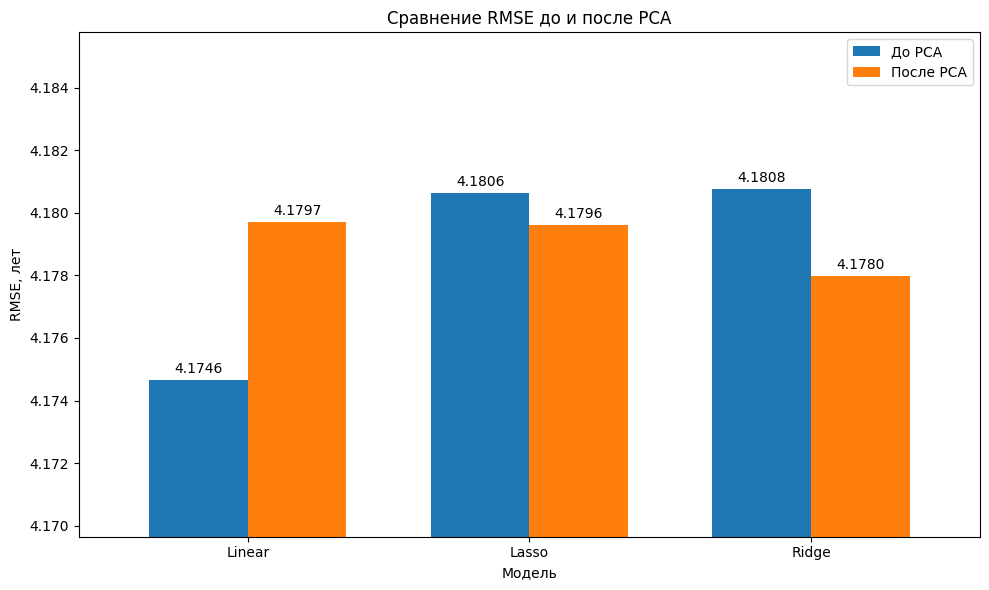

In [33]:
rmse_data = pd.DataFrame({
    "Модель": ["Linear", "Lasso", "Ridge"],
    "До PCA": [
        comparison_df.loc[
            comparison_df["Модель"] == name, "RMSE"
        ].iloc[0]
        for name in ["Linear", "Lasso", "Ridge"]
    ],
    "После PCA": [
        comparison_df.loc[
            comparison_df["Модель"] == name + " + PCA", "RMSE"
        ].iloc[0]
        for name in ["Linear", "Lasso", "Ridge"]
    ]
})

ax = rmse_data.plot(
    x="Модель",
    y=["До PCA", "После PCA"],
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Сравнение RMSE до и после PCA")
plt.xlabel("Модель")
plt.ylabel("RMSE, лет")
plt.xticks(rotation=0)

# Увеличиваем масштаб, чтобы показать небольшие различия
plt.ylim(
    rmse_data[["До PCA", "После PCA"]].min().min() - 0.005,
    rmse_data[["До PCA", "После PCA"]].max().max() + 0.005
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.legend()
plt.tight_layout()
plt.show()

На графике представлено попарное сравнение среднеквадратичной ошибки моделей Linear Regression, Lasso и Ridge до и после применения метода главных компонент. Для наглядности вертикальная ось отображает ограниченный диапазон значений RMSE.

Результаты показывают, что применение PCA не привело к существенному изменению точности прогнозирования. Все модели демонстрируют близкие значения RMSE - около 4,18 года.


Таким образом, PCA позволил уменьшить размерность признакового пространства и устранить мультиколлинеарность, практически не ухудшив качество прогнозирования. Это свидетельствует о возможности использования главных компонент вместо исходных признаков при сохранении сопоставимой точности моделей.

In [34]:
rmse_data["Изменение RMSE"] = (
    rmse_data["После PCA"] - rmse_data["До PCA"]
)

display(rmse_data.round(4))

,Модель,До PCA,После PCA,Изменение RMSE
0,Linear,4.1746,4.1797,0.0050
1,Lasso,4.1806,4.1796,-0.0010
2,Ridge,4.1808,4.1780,-0.0028


### 5. Заключение

В ходе лабораторной работы были изучены методы линейной регрессии, Lasso и Ridge, а также метод главных компонент PCA.

Для исследования использован датасет Life Expectancy (WHO), содержащий сведения о продолжительности жизни и социально-экономических показателях стран.

Был проведён первичный анализ данных, построены распределения признаков и корреляционная матрица. Выполнена обработка пропущенных значений, после которой осталось 1649 наблюдений.

На основе подготовленных данных обучены три регрессионные модели. Их качество оценено с помощью RMSE, R² и MAPE. Дополнительно исследованы остатки моделей.

Для снижения размерности и устранения мультиколлинеарности применён PCA. После преобразования признаков модели обучены повторно, а полученные результаты сопоставлены с исходными.

**Итоговые выводы**

По результатам проведённого исследования установлено, что все три регрессионные модели - Linear Regression, Lasso и Ridge - демонстрируют сопоставимое качество прогнозирования ожидаемой продолжительности жизни.

Наилучший результат по метрике RMSE показала обычная линейная регрессия без PCA со значением около 4,175 года и коэффициентом детерминации R² ≈ 0,729. Это означает, что модель объясняет примерно 72,9% вариации продолжительности жизни в тестовой выборке.

Применение метода главных компонент позволило уменьшить количество признаков с 20 до 14, сохранив около 95,52% общей дисперсии, а также устранить мультиколлинеарность между преобразованными признаками.

После PCA значения метрик изменились незначительно. Для обычной линейной регрессии наблюдалось небольшое увеличение RMSE, тогда как для Lasso и Ridge ошибка немного снизилась. Наименьшее значение MAPE, около 5,02%, показала модель Ridge с PCA.

Таким образом, PCA оказался эффективным для уменьшения размерности и устранения мультиколлинеарности, но не обеспечил существенного повышения точности прогнозирования. Приоритетной моделью по RMSE является Linear Regression без PCA, однако модели на главных компонентах представляют интерес благодаря меньшему количеству взаимно некоррелированных признаков.

### 6. Список использованных источников
1. Kaggle. Набор данных «Ожидаемая продолжительность жизни (ВОЗ)» [Электронный ресурс]. - URL: https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who (дата обращения: 14.10.2026).

2. Scikit-learn. Официальная документация библиотеки машинного обучения [Электронный ресурс]. - URL: https://scikit-learn.org/stable/ (дата обращения: 14.10.2026).

3. Pandas. Официальная документация библиотеки для анализа и обработки данных [Электронный ресурс]. - URL: https://pandas.pydata.org/docs/ (дата обращения: 14.10.2026).

### 7. Приложение



In [ ]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor


BASE_DIR = Path(__file__).resolve().parent

DATA_PATH = BASE_DIR / "data" / "Life Expectancy Data.csv"
FIGURES_DIR = BASE_DIR / "results" / "figures"
TABLES_DIR = BASE_DIR / "results" / "tables"

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

print("Загрузка данных")
print("Размер датасета:", df.shape)
print(df.head())
df.info()


print("\nОписательные статистики")

statistics = df.describe().T
print(statistics.round(2))

statistics.to_csv(
    TABLES_DIR / "descriptive_statistics.csv",
    encoding="utf-8-sig"
)

print("\nПропущенные значения")

missing = df.isna().sum()

missing_table = pd.DataFrame({
    "Количество": missing,
    "Доля (%)": missing / len(df) * 100
})

print(missing_table.sort_values("Количество", ascending=False))

missing_table.to_csv(
    TABLES_DIR / "missing_values.csv",
    encoding="utf-8-sig"
)

plt.figure(figsize=(10, 6))
missing[missing > 0].sort_values().plot(kind="barh")
plt.title("Количество пропущенных значений")
plt.xlabel("Количество пропусков")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_values.png", dpi=200)
plt.close()

print("\nДубликаты")
print("Полных дубликатов:", df.duplicated().sum())
print(
    "Дубликатов Country-Year:",
    df.duplicated(subset=["Country", "Year"]).sum()
)


plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Life expectancy",
    bins=30,
    kde=True
)

plt.title("Распределение продолжительности жизни")
plt.xlabel("Продолжительность жизни, лет")
plt.ylabel("Количество наблюдений")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "life_expectancy_distribution.png", dpi=200)
plt.close()


numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].hist(figsize=(18, 18), bins=25)

plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "numeric_distributions.png", dpi=200)
plt.close()


features = ["Schooling", "Adult Mortality", "GDP", "BMI"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flat, features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="Life expectancy",
        alpha=0.5,
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "features_vs_target.png", dpi=200)
plt.close()


corr_initial = df.select_dtypes(
    include=np.number
).corr(method="pearson")

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_initial,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Корреляционная матрица исходного датасета")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_matrix.png", dpi=200)
plt.close()



outlier_features = [
    "Life expectancy",
    "Adult Mortality",
    "GDP",
    "Schooling"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, outlier_features):
    sns.boxplot(data=df, x=feature, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "outliers_boxplot.png", dpi=200)
plt.close()



print("\nОчистка данных")

df_clean = df.dropna().copy()

print("До очистки:", df.shape)
print("После очистки:", df_clean.shape)
print("Удалено строк:", len(df) - len(df_clean))

rows = pd.Series({
    "До очистки": len(df),
    "После очистки": len(df_clean)
})

plt.figure(figsize=(7, 4))
rows.plot(kind="bar")
plt.title("Количество наблюдений до и после очистки")
plt.ylabel("Количество наблюдений")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "data_cleaning.png", dpi=200)
plt.close()



df_clean["Status"] = df_clean["Status"].map({
    "Developing": 0,
    "Developed": 1
})

plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="Status")
plt.title("Распределение по статусу страны")
plt.xlabel("0 — Developing, 1 — Developed")
plt.ylabel("Количество наблюдений")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "status_distribution.png", dpi=200)
plt.close()



X = df_clean.drop(columns=["Country", "Life expectancy"])
y = df_clean["Life expectancy"]
groups = df_clean["Country"]

print("Размер X:", X.shape)
print("Размер y:", y.shape)


splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]

print("\nРазделение данных")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

common_countries = (
    set(groups.iloc[train_idx]) &
    set(groups.iloc[test_idx])
)

print("Общие страны:", common_countries)

sizes = pd.Series({
    "Обучающая": len(X_train),
    "Тестовая": len(X_test)
})

plt.figure(figsize=(7, 4))
sizes.plot(kind="bar")
plt.title("Разделение на train и test")
plt.ylabel("Количество наблюдений")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "train_test_split.png", dpi=200)
plt.close()


train_data = X_train.copy()
train_data["Life expectancy"] = y_train

corr_train = train_data.corr(method="pearson")

corr_train.to_csv(
    TABLES_DIR / "train_correlations.csv",
    encoding="utf-8-sig"
)

print("\nКорреляции с целевой переменной")

target_corr = corr_train["Life expectancy"].drop(
    "Life expectancy"
)

target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

print(target_corr.round(3))


print("\nVIF до PCA")

scaler_vif = StandardScaler()
X_vif = scaler_vif.fit_transform(X_train)

vif_table = pd.DataFrame({
    "Признак": X_train.columns,
    "VIF": [
        variance_inflation_factor(X_vif, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_table = vif_table.sort_values("VIF", ascending=False)

print(vif_table.round(2))

vif_table.to_csv(
    TABLES_DIR / "vif_before_pca.csv",
    index=False,
    encoding="utf-8-sig"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=vif_table,
    x="VIF",
    y="Признак"
)

plt.axvline(10, color="red", linestyle="--")
plt.title("VIF до PCA")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vif_before_pca.png", dpi=200)
plt.close()



models = {
    "Linear": LinearRegression(),
    "Lasso": Lasso(max_iter=30000),
    "Ridge": Ridge()
}

alphas = [0.001, 0.01, 0.1, 1, 10, 100]

cv = GroupKFold(n_splits=5)

trained_models = {}
results = []
cv_results = []


print("\nОбучение моделей")

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    if name == "Linear":
        params = {}
    else:
        params = {"model__alpha": alphas}

    search = GridSearchCV(
        pipeline,
        param_grid=params,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    search.fit(X_train, y_train, groups=groups_train)

    trained_models[name] = search.best_estimator_

    cv_results.append({
        "Модель": name,
        "Alpha": search.best_params_.get("model__alpha", np.nan),
        "CV RMSE": -search.best_score_
    })

    print(name)
    print("Лучшие параметры:", search.best_params_)
    print("CV RMSE:", round(-search.best_score_, 3))

    for sample, X_part, y_part in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test)
    ]:

        y_pred = search.predict(X_part)

        rmse = np.sqrt(mean_squared_error(y_part, y_pred))
        r2 = r2_score(y_part, y_pred)
        mape = mean_absolute_percentage_error(y_part, y_pred) * 100

        results.append({
            "Модель": name,
            "Выборка": sample,
            "RMSE": rmse,
            "R²": r2,
            "MAPE (%)": mape
        })


results_df = pd.DataFrame(results)
cv_df = pd.DataFrame(cv_results)

print("\nМетрики до PCA")
print(results_df.round(3).to_string(index=False))

print("\nРезультаты кросс-валидации")
print(cv_df.round(3).to_string(index=False))

results_df.to_csv(
    TABLES_DIR / "metrics_before_pca.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_df.to_csv(
    TABLES_DIR / "cv_results.csv",
    index=False,
    encoding="utf-8-sig"
)

test_results = results_df[
    results_df["Выборка"] == "Test"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=test_results,
    x="Модель",
    y="RMSE"
)

plt.title("Сравнение RMSE до PCA")
plt.ylabel("RMSE, лет")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "rmse_before_pca.png", dpi=200)
plt.close()


print("\nКоэффициенты моделей")

coef_table = pd.DataFrame({
    name: trained_models[name].named_steps["model"].coef_
    for name in models
}, index=X_train.columns)

print(coef_table.round(3))

coef_table.to_csv(
    TABLES_DIR / "model_coefficients.csv",
    encoding="utf-8-sig"
)


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    ax.scatter(y_pred, residuals, alpha=0.5)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Предсказанное значение")
    ax.set_ylabel("Остатки, лет")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "residuals_before_pca.png", dpi=200)
plt.close()



print("\nPCA")

scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)

pca_full = PCA()
pca_full.fit(X_train_scaled)

variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Исходное число признаков:", X_train.shape[1])
print("Выбрано компонент:", n_components)
print(
    "Сохранённая дисперсия:",
    round(cumulative_variance[n_components - 1] * 100, 2),
    "%"
)

pca_variance = pd.DataFrame({
    "Компонента": range(1, len(variance) + 1),
    "Доля дисперсии": variance,
    "Накопленная доля": cumulative_variance
})

pca_variance.to_csv(
    TABLES_DIR / "pca_variance.csv",
    index=False,
    encoding="utf-8-sig"
)


plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(variance) + 1),
    variance,
    marker="o"
)

plt.title("График каменистой осыпи")
plt.xlabel("Номер главной компоненты")
plt.ylabel("Доля объяснённой дисперсии")
plt.grid(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "pca_scree.png", dpi=200)
plt.close()


plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    0.95,
    color="red",
    linestyle="--",
    label="95% дисперсии"
)

plt.title("Накопленная объяснённая дисперсия")
plt.xlabel("Количество компонент")
plt.ylabel("Накопленная доля дисперсии")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "pca_cumulative.png", dpi=200)
plt.close()


pca_selected = PCA(n_components=0.95)
X_pca = pca_selected.fit_transform(X_train_scaled)

print("\nРазмер матрицы после PCA:", X_pca.shape)

vif_after = pd.DataFrame({
    "Компонента": [
        f"PC{i+1}" for i in range(X_pca.shape[1])
    ],
    "VIF": [
        variance_inflation_factor(X_pca, i)
        for i in range(X_pca.shape[1])
    ]
})

print("\nVIF после PCA")
print(vif_after.round(3))

vif_after.to_csv(
    TABLES_DIR / "vif_after_pca.csv",
    index=False,
    encoding="utf-8-sig"
)

loadings = pd.DataFrame(
    pca_selected.components_.T,
    index=X_train.columns,
    columns=[
        f"PC{i+1}" for i in range(X_pca.shape[1])
    ]
)

print("\nНагрузки первых трех компонент")
print(loadings.iloc[:, :3].round(3))

loadings.to_csv(
    TABLES_DIR / "pca_loadings.csv",
    encoding="utf-8-sig"
)


print("\nМодели после PCA")

trained_pca_models = {}
pca_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95)),
        ("model", model)
    ])

    if name == "Linear":
        params = {}
    else:
        params = {"model__alpha": alphas}

    search = GridSearchCV(
        pipeline,
        param_grid=params,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    search.fit(X_train, y_train, groups=groups_train)

    model_name = name + " + PCA"
    trained_pca_models[model_name] = search.best_estimator_

    print(model_name)
    print("Лучшие параметры:", search.best_params_)
    print("CV RMSE:", round(-search.best_score_, 3))

    for sample, X_part, y_part in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test)
    ]:

        y_pred = search.predict(X_part)

        rmse = np.sqrt(mean_squared_error(y_part, y_pred))
        r2 = r2_score(y_part, y_pred)
        mape = mean_absolute_percentage_error(y_part, y_pred) * 100

        pca_results.append({
            "Модель": model_name,
            "Выборка": sample,
            "RMSE": rmse,
            "R²": r2,
            "MAPE (%)": mape
        })


pca_results_df = pd.DataFrame(pca_results)

print("\nМетрики после PCA")
print(pca_results_df.round(3).to_string(index=False))

pca_results_df.to_csv(
    TABLES_DIR / "metrics_after_pca.csv",
    index=False,
    encoding="utf-8-sig"
)


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, trained_pca_models.items()):

    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    ax.scatter(y_pred, residuals, alpha=0.5)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Предсказанное значение")
    ax.set_ylabel("Остатки, лет")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "residuals_after_pca.png", dpi=200)
plt.close()


comparison_df = pd.concat(
    [results_df, pca_results_df],
    ignore_index=True
)

comparison_df = comparison_df[
    comparison_df["Выборка"] == "Test"
].copy()

print("\nИтоговое сравнение")
print(comparison_df.round(3).to_string(index=False))

comparison_df.to_csv(
    TABLES_DIR / "final_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


rmse_data = pd.DataFrame({
    "Модель": ["Linear", "Lasso", "Ridge"],
    "До PCA": [
        comparison_df.loc[
            comparison_df["Модель"] == name, "RMSE"
        ].iloc[0]
        for name in ["Linear", "Lasso", "Ridge"]
    ],
    "После PCA": [
        comparison_df.loc[
            comparison_df["Модель"] == name + " + PCA", "RMSE"
        ].iloc[0]
        for name in ["Linear", "Lasso", "Ridge"]
    ]
})

ax = rmse_data.plot(
    x="Модель",
    y=["До PCA", "После PCA"],
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Сравнение RMSE до и после PCA")
plt.xlabel("Модель")
plt.ylabel("RMSE, лет")
plt.xticks(rotation=0)

plt.ylim(4.15, 4.20)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "rmse_comparison.png",
    dpi=300
)

plt.show()


best_model = comparison_df.loc[
    comparison_df["RMSE"].idxmin()
]

print("\nЛучшая модель по RMSE")
print("Модель:", best_model["Модель"])
print("RMSE:", round(best_model["RMSE"], 3))
print("R²:", round(best_model["R²"], 3))
print("MAPE:", round(best_model["MAPE (%)"], 3), "%")

